In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import pandas as pd
import numpy as np

# Cargar la base de datos
df = pd.read_csv("../datos/AB_NYC_2019.csv")

# Mostrar los primeros registros
display(df.head())

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [3]:
print("Número de registros:", df.shape[0])
print("Número de variables:", df.shape[1])

Número de registros: 48895
Número de variables: 16


In [4]:
# Identificar valores faltantes

faltantes = df.isnull().sum()

print("Valores faltantes por variable:")
display(faltantes)

# Porcentaje de valores faltantes
porcentaje = (df.isnull().sum() / len(df)) * 100

print("Porcentaje de valores faltantes:")
display(porcentaje.sort_values(ascending=False))

Valores faltantes por variable:


id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64

Porcentaje de valores faltantes:


last_review                       20.558339
reviews_per_month                 20.558339
host_name                          0.042949
name                               0.032723
neighbourhood_group                0.000000
neighbourhood                      0.000000
id                                 0.000000
host_id                            0.000000
longitude                          0.000000
latitude                           0.000000
room_type                          0.000000
price                              0.000000
number_of_reviews                  0.000000
minimum_nights                     0.000000
calculated_host_listings_count     0.000000
availability_365                   0.000000
dtype: float64

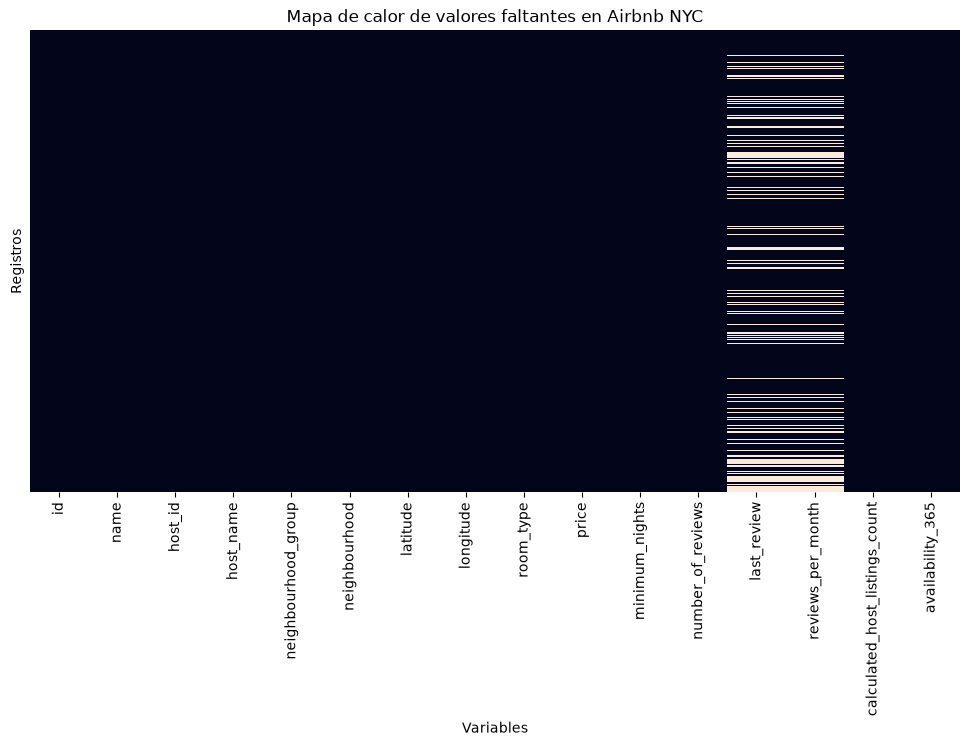

In [5]:
# Visualizar los valores faltantes

plt.figure(figsize=(12, 6))

sns.heatmap(df.isnull(), cbar=False, yticklabels=False)

plt.title("Mapa de calor de valores faltantes en Airbnb NYC")
plt.xlabel("Variables")
plt.ylabel("Registros")

plt.show()

In [6]:
# Cantidad y porcentaje de datos faltantes

tabla_faltantes = pd.DataFrame({
    "Cantidad": df.isnull().sum(),
    "Porcentaje": (df.isnull().sum() / len(df)) * 100
})

display(tabla_faltantes.sort_values(
    by="Porcentaje",
    ascending=False
))

,Cantidad,Porcentaje
last_review,10052,20.558339
reviews_per_month,10052,20.558339
host_name,21,0.042949
name,16,0.032723
neighbourhood_group,0,0.000000
neighbourhood,0,0.000000
id,0,0.000000
host_id,0,0.000000
longitude,0,0.000000
latitude,0,0.000000


In [7]:
faltantes = df.isna().sum()
porcentaje = (faltantes / len(df) * 100).round(2)
pd.DataFrame({"faltantes": faltantes, "%": porcentaje})[faltantes > 0]

,faltantes,%
name,16,0.03
host_name,21,0.04
last_review,10052,20.56
reviews_per_month,10052,20.56


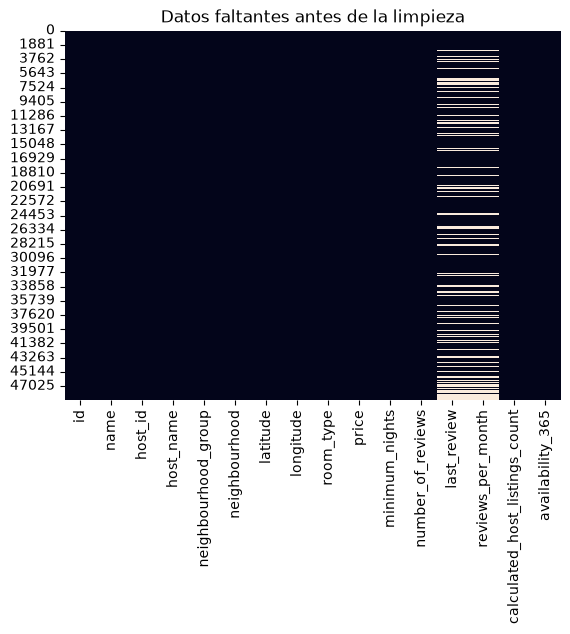

Alojamientos sin reseñas: 10052
Coinciden con los faltantes: True


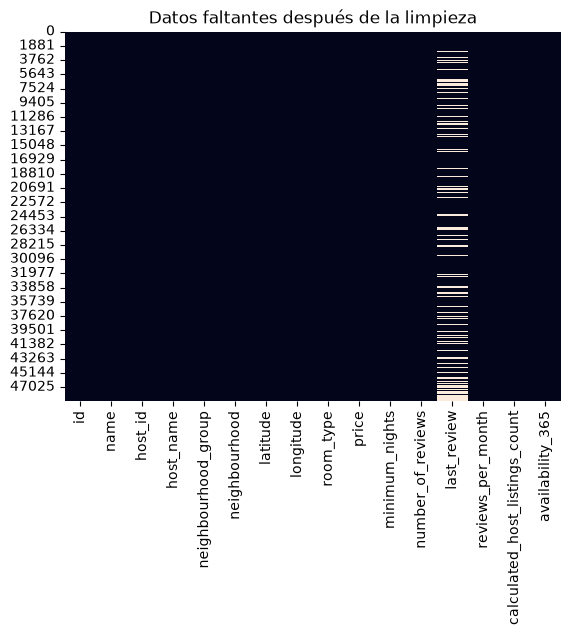

In [8]:
# %% [markdown]
# ## 2. Manejo de datos faltantes  (Integrante B)
# Primero se visualizan los valores faltantes con un mapa de calor.

# %%
sns.heatmap(df.isna(), cbar=False)
plt.title("Datos faltantes antes de la limpieza")
plt.show()

faltantes = df.isna().sum()
porcentaje = (faltantes / len(df) * 100).round(2)
pd.DataFrame({"faltantes": faltantes, "%": porcentaje})[faltantes > 0]

# %% [markdown]
# **Diagnóstico:** solo 4 variables tienen faltantes. `name` (0.03 %) y
# `host_name` (0.04 %) tienen muy pocos. `last_review` y `reviews_per_month`
# tienen 10052 faltantes (20.56 %), la misma cantidad en ambas, lo que sugiere
# que corresponden a alojamientos sin reseñas.

# %%
sin_resenas = df["number_of_reviews"] == 0
print("Alojamientos sin reseñas:", sin_resenas.sum())
print("Coinciden con los faltantes:", (df["last_review"].isna() == sin_resenas).all())

# %% [markdown]
# **Decisiones:**
# - `name` y `host_name`: se rellenan con "Desconocido" porque son menos del 0.1 %
#   y eliminar las filas haría perder información útil (precio, ubicación).
# - `reviews_per_month`: se imputa con 0, porque el faltante significa que el
#   alojamiento no tiene reseñas.
# - `last_review`: se convierte a fecha y se deja como `NaT`, porque sin reseñas
#   no existe una fecha y imputar una distorsionaría los datos.

# %%
df["name"] = df["name"].fillna("Desconocido")
df["host_name"] = df["host_name"].fillna("Desconocido")
df["reviews_per_month"] = df["reviews_per_month"].fillna(0)
df["last_review"] = pd.to_datetime(df["last_review"])

sns.heatmap(df.isna(), cbar=False)
plt.title("Datos faltantes después de la limpieza")
plt.show()

# %% [markdown]
# **Conclusión:** el 20.56 % de faltantes se debía a alojamientos sin reseñas,
# no a errores de captura. Tras la limpieza, solo `last_review` conserva vacíos,
# y es intencional porque esa fecha no existe.

In [9]:
print("Filas duplicadas completas:", df.duplicated().sum())
print("IDs repetidos:", df["id"].duplicated().sum())

Filas duplicadas completas: 0
IDs repetidos: 0


In [10]:
cols_texto = ["name", "host_name", "neighbourhood_group", "neighbourhood", "room_type"]

for col in cols_texto:
    n_espacios = (df[col] != df[col].str.strip()).sum()
    n_mayus = (df[col] != df[col].str.title()).sum()
    print(f"{col}: {n_espacios} con espacios extra, {df[col].nunique()} valores únicos")

print(df["neighbourhood_group"].value_counts())
print(df["room_type"].value_counts())

name: 238 con espacios extra, 47906 valores únicos
host_name: 0 con espacios extra, 11453 valores únicos
neighbourhood_group: 0 con espacios extra, 5 valores únicos
neighbourhood: 0 con espacios extra, 221 valores únicos
room_type: 0 con espacios extra, 3 valores únicos
neighbourhood_group
Manhattan        21661
Brooklyn         20104
Queens            5666
Bronx             1091
Staten Island      373
Name: count, dtype: int64
room_type
Entire home/apt    25409
Private room       22326
Shared room         1160
Name: count, dtype: int64


In [11]:
# %% [markdown]
# ## 4. Valores inconsistentes y duplicados  (Integrante B)
# Se revisan los registros duplicados y la consistencia de las variables de texto.

# %%
print("Filas duplicadas completas:", df.duplicated().sum())
print("IDs repetidos:", df["id"].duplicated().sum())

# %% [markdown]
# **Duplicados:** no hay filas duplicadas ni IDs repetidos. Como cada `id`
# identifica un alojamiento único, no se elimina ningún registro y se conserva
# toda la información.

# %%
cols_texto = ["name", "host_name", "neighbourhood_group", "neighbourhood", "room_type"]

for col in cols_texto:
    n_espacios = (df[col] != df[col].str.strip()).sum()
    print(f"{col}: {n_espacios} con espacios extra, {df[col].nunique()} valores únicos")

print(df["neighbourhood_group"].value_counts())
print(df["room_type"].value_counts())

# %% [markdown]
# **Inconsistencias:** `host_name`, `neighbourhood_group`, `neighbourhood` y
# `room_type` no tienen espacios extra. Las categorías están bien escritas:
# `neighbourhood_group` tiene 5 valores (Manhattan, Brooklyn, Queens, Bronx y
# Staten Island) y `room_type` tiene 3 (Entire home/apt, Private room y Shared
# room), sin variantes repetidas. El único problema está en `name`, donde 238
# nombres tienen espacios al inicio o al final. Se eliminan porque el mismo texto
# se contaría como distinto. No se cambian mayúsculas en `room_type` ni en
# `neighbourhood_group` porque ya son consistentes.

# %%
df["name"] = df["name"].str.strip()

print("Nombres con espacios extra después:", (df["name"] != df["name"].str.strip()).sum())
print("Registros después de la limpieza:", len(df))

# %% [markdown]
# **Conclusión:** el conjunto no tenía duplicados y las categorías ya eran
# consistentes. La limpieza se limitó a quitar los espacios extra de 238 nombres
# en `name`. Se mantienen los 48.895 registros, listos para filtrar y agrupar.

Filas duplicadas completas: 0
IDs repetidos: 0
name: 238 con espacios extra, 47906 valores únicos
host_name: 0 con espacios extra, 11453 valores únicos
neighbourhood_group: 0 con espacios extra, 5 valores únicos
neighbourhood: 0 con espacios extra, 221 valores únicos
room_type: 0 con espacios extra, 3 valores únicos
neighbourhood_group
Manhattan        21661
Brooklyn         20104
Queens            5666
Bronx             1091
Staten Island      373
Name: count, dtype: int64
room_type
Entire home/apt    25409
Private room       22326
Shared room         1160
Name: count, dtype: int64
Nombres con espacios extra después: 0
Registros después de la limpieza: 48895


In [12]:
# %% [markdown]
# ## 6. Filtrado y condiciones en pandas  (Integrante B)

# %%
# Filtro 1: alojamientos de lujo (más de 500 dólares por noche)
caros = df[df["price"] > 500]
print("Cantidad:", len(caros), "|", round(len(caros) / len(df) * 100, 2), "%")
print(caros["neighbourhood_group"].value_counts())

# %%
# Filtro 2: habitaciones privadas baratas en Manhattan (menos de 100 dólares)
baratas = df[(df["room_type"] == "Private room")
             & (df["neighbourhood_group"] == "Manhattan")
             & (df["price"] < 100)]
print("Cantidad:", len(baratas))
print("Precio promedio:", round(baratas["price"].mean(), 2))

# %%
# Filtro 3: muy populares (más de 100 reseñas) y con alta disponibilidad
populares = df[(df["number_of_reviews"] > 100) & (df["availability_365"] > 300)]
print("Cantidad:", len(populares))
print(populares["room_type"].value_counts())

# %%
# Filtro 4: estadías largas (30 noches o más)
largas = df[df["minimum_nights"] >= 30]
print("Cantidad:", len(largas), "|", round(len(largas) / len(df) * 100, 2), "%")
print("Precio promedio:", round(largas["price"].mean(), 2))

# %%
# Filtro 5: anfitriones con más de 10 propiedades
grandes = df[df["calculated_host_listings_count"] > 10]
print("Cantidad:", len(grandes), "|", round(len(grandes) / len(df) * 100, 2), "%")
print(grandes["neighbourhood_group"].value_counts())

Cantidad: 1044 | 2.14 %
neighbourhood_group
Manhattan        773
Brooklyn         229
Queens            29
Bronx              7
Staten Island      6
Name: count, dtype: int64
Cantidad: 4787
Precio promedio: 70.45
Cantidad: 506
room_type
Private room       288
Entire home/apt    199
Shared room         19
Name: count, dtype: int64
Cantidad: 4507 | 9.22 %
Precio promedio: 191.89
Cantidad: 2967 | 6.07 %
neighbourhood_group
Manhattan    2227
Brooklyn      496
Queens        230
Bronx          14
Name: count, dtype: int64


In [13]:
# %% [markdown]
# ## 6. Filtrado y condiciones en pandas  (Integrante B)

# %%
# Filtro 1: alojamientos de lujo (más de 500 dólares por noche)
caros = df[df["price"] > 500]
print("Cantidad:", len(caros), "|", round(len(caros) / len(df) * 100, 2), "%")
print(caros["neighbourhood_group"].value_counts())

# %% [markdown]
# **Conclusión filtro 1:** solo 1.044 alojamientos (2,14 %) cuestan más de 500
# dólares por noche. El 74 % está en Manhattan (773) y el 22 % en Brooklyn (229),
# así que el segmento de lujo se concentra en esas dos zonas.

# %%
# Filtro 2: habitaciones privadas baratas en Manhattan (menos de 100 dólares)
baratas = df[(df["room_type"] == "Private room")
             & (df["neighbourhood_group"] == "Manhattan")
             & (df["price"] < 100)]
print("Cantidad:", len(baratas))
print("Precio promedio:", round(baratas["price"].mean(), 2))

# %% [markdown]
# **Conclusión filtro 2:** hay 4.787 habitaciones privadas en Manhattan por menos
# de 100 dólares, con un precio promedio de 70,45. Aun en la zona más cara de la
# ciudad existe una oferta económica considerable (cerca del 10 % del total).

# %%
# Filtro 3: muy populares (más de 100 reseñas) y con alta disponibilidad
populares = df[(df["number_of_reviews"] > 100) & (df["availability_365"] > 300)]
print("Cantidad:", len(populares))
print(populares["room_type"].value_counts())

# %% [markdown]
# **Conclusión filtro 3:** solo 506 alojamientos combinan más de 100 reseñas y más
# de 300 días disponibles al año. Predominan las habitaciones privadas (288, el
# 57 %) sobre las viviendas completas (199, el 39 %), lo que sugiere que las
# habitaciones privadas son las más demandadas y las que más rotan.

# %%
# Filtro 4: estadías largas (30 noches o más)
largas = df[df["minimum_nights"] >= 30]
print("Cantidad:", len(largas), "|", round(len(largas) / len(df) * 100, 2), "%")
print("Precio promedio estadías largas:", round(largas["price"].mean(), 2))
print("Precio promedio general:", round(df["price"].mean(), 2))

# %% [markdown]
# **Conclusión filtro 4:** el 9,22 % de los alojamientos (4.507) exige 30 noches o
# más, es decir, funcionan como alquiler de larga estancia y no como turismo. Su
# precio promedio (191,89) es superior al promedio general de la base.

# %%
# Filtro 5: anfitriones con más de 10 propiedades
grandes = df[df["calculated_host_listings_count"] > 10]
print("Cantidad:", len(grandes), "|", round(len(grandes) / len(df) * 100, 2), "%")
print(grandes["neighbourhood_group"].value_counts())

# %% [markdown]
# **Conclusión filtro 5:** el 6,07 % de los alojamientos (2.967) pertenece a
# anfitriones con más de 10 propiedades. El 75 % está en Manhattan (2.227), lo que
# indica que allí la oferta está más profesionalizada y no depende solo de
# propietarios individuales.

Cantidad: 1044 | 2.14 %
neighbourhood_group
Manhattan        773
Brooklyn         229
Queens            29
Bronx              7
Staten Island      6
Name: count, dtype: int64
Cantidad: 4787
Precio promedio: 70.45
Cantidad: 506
room_type
Private room       288
Entire home/apt    199
Shared room         19
Name: count, dtype: int64
Cantidad: 4507 | 9.22 %
Precio promedio estadías largas: 191.89
Precio promedio general: 152.72
Cantidad: 2967 | 6.07 %
neighbourhood_group
Manhattan    2227
Brooklyn      496
Queens        230
Bronx          14
Name: count, dtype: int64
